In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RAW = Path("../data/raw")
PROC = Path("../data/processed")
CFG = Path("../configs")

print(PROC / "sales_subset_wide.parquet", (PROC / "sales_subset_wide.parquet").exists())
print(CFG / "subset_ids.csv", (CFG / "subset_ids.csv").exists())

..\data\processed\sales_subset_wide.parquet True
..\configs\subset_ids.csv True


In [2]:
subset = pd.read_csv(CFG / "subset_ids.csv")
wide = pd.read_parquet(PROC / "sales_subset_wide.parquet")
cal = pd.read_csv(RAW / "calendar.csv")
day_cols = [c for c in wide.columns if c.startswith("d_")]

long = wide.melt(
    id_vars=["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"],
    value_vars=day_cols, var_name="d", value_name="sales")

long = long.merge(cal, on="d", how="left")
long["date"] = pd.to_datetime(long["date"])

prices = pd.read_csv(RAW / "sell_prices.csv")
prices = prices[prices["store_id"].isin(subset["store_id"].unique())
                & prices["item_id"].isin(subset["item_id"].unique())]
long = long.merge(prices, on=["store_id", "item_id", "wm_yr_wk"], how="left")

assert len(long) == len(wide) * len(day_cols)   # ghép giá không được làm tăng số dòng
print(long.shape)
long.head()

(576477, 22)


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,...,month,year,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI,sell_price
0,FOODS_1_048_CA_3_evaluation,FOODS_1_048,FOODS_1,FOODS,CA_3,CA,d_1,0,2011-01-29,11101,...,1,2011,NaN,NaN,NaN,NaN,0,0,0,NaN
1,FOODS_1_059_CA_3_evaluation,FOODS_1_059,FOODS_1,FOODS,CA_3,CA,d_1,0,2011-01-29,11101,...,1,2011,NaN,NaN,NaN,NaN,0,0,0,NaN
2,FOODS_1_069_CA_3_evaluation,FOODS_1_069,FOODS_1,FOODS,CA_3,CA,d_1,5,2011-01-29,11101,...,1,2011,NaN,NaN,NaN,NaN,0,0,0,2.18
3,FOODS_1_072_CA_3_evaluation,FOODS_1_072,FOODS_1,FOODS,CA_3,CA,d_1,0,2011-01-29,11101,...,1,2011,NaN,NaN,NaN,NaN,0,0,0,NaN
4,FOODS_1_078_CA_3_evaluation,FOODS_1_078,FOODS_1,FOODS,CA_3,CA,d_1,0,2011-01-29,11101,...,1,2011,NaN,NaN,NaN,NaN,0,0,0,NaN


In [3]:
long = long.sort_values(["id", "date"]).reset_index(drop=True)

first_sale = (long.loc[long["sales"] > 0].groupby("id")["date"].min()
              .rename("first_date").reset_index())
long = long.merge(first_sale, on="id", how="left")
long["live"] = long["date"] >= long["first_date"]
long = long.merge(subset[["id", "volume_group"]], on="id", how="left")

live = long[long["live"]].copy()

# "rel" = số bán so với mức trung bình của chính chuỗi đó (1.0 = bằng trung bình)
live["rel"] = live["sales"] / live.groupby("id")["sales"].transform("mean")

# cờ SNAP đúng theo bang của từng cửa hàng
live["snap"] = np.select(
    [live["state_id"] == "CA", live["state_id"] == "TX", live["state_id"] == "WI"],
    [live["snap_CA"], live["snap_TX"], live["snap_WI"]])
print(long.shape, live.shape)

(576477, 25) (499718, 27)


tỉ lệ ngày bán 0: 0.475
count    297.000
mean       0.478
std        0.214
min        0.041
25%        0.319
50%        0.489
75%        0.623
max        0.934
Name: is_zero, dtype: float64
volume_group      0      1      2
store_id                         
CA_3          0.651  0.394  0.203
TX_2          0.771  0.510  0.305
WI_1          0.705  0.474  0.284
count    262358.00
mean          5.32
std          15.66
min           1.00
25%           1.00
50%           2.00
75%           5.00
max         763.00
Name: sales, dtype: float64


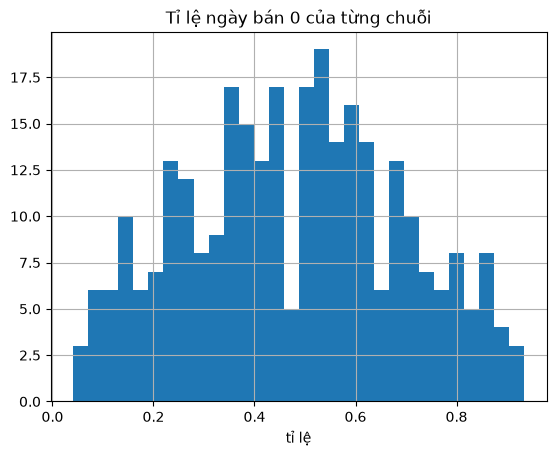

In [4]:
live["is_zero"] = live["sales"] == 0
print("tỉ lệ ngày bán 0:", round(live["is_zero"].mean(), 3))

per_series = live.groupby("id")["is_zero"].mean()
print(per_series.describe().round(3))
print(live.pivot_table(index="store_id", columns="volume_group",
                       values="is_zero", aggfunc="mean").round(3))

print(live.loc[live["sales"] > 0, "sales"].describe().round(2))
per_series.hist(bins=30)
plt.title("Tỉ lệ ngày bán 0 của từng chuỗi"); plt.xlabel("tỉ lệ"); plt.show()

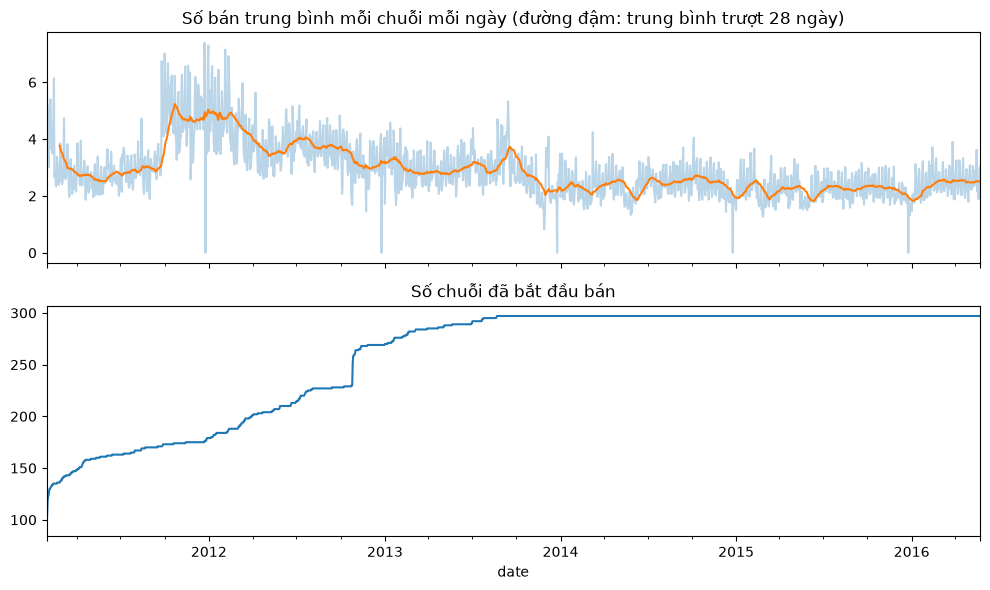

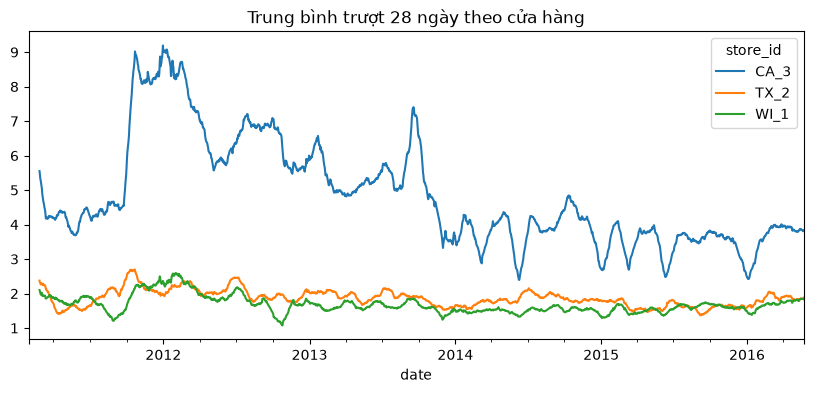

2011-01-29 00:00:00 2016-05-22 00:00:00


In [5]:
daily = live.groupby("date").agg(avg_sales=("sales", "mean"), n_series=("id", "nunique"))
daily["avg_28d"] = daily["avg_sales"].rolling(28).mean()

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
daily["avg_sales"].plot(ax=ax[0], alpha=0.3)
daily["avg_28d"].plot(ax=ax[0])
ax[0].set_title("Số bán trung bình mỗi chuỗi mỗi ngày (đường đậm: trung bình trượt 28 ngày)")
daily["n_series"].plot(ax=ax[1]); ax[1].set_title("Số chuỗi đã bắt đầu bán")
plt.tight_layout(); plt.show()

(live.groupby(["date", "store_id"])["sales"].mean().unstack()
 .rolling(28).mean().plot(figsize=(10, 4), title="Trung bình trượt 28 ngày theo cửa hàng"))
plt.show()
print(live["date"].min(), live["date"].max())

In [6]:
# số chuỗi tham gia và mức bán theo năm
yr = live.groupby("year").agg(avg_sales=("sales", "mean"),
                              n_series=("id", "nunique"), n_days=("date", "nunique"))
print(yr.round(3))

# chỉ xét chuỗi đã bán từ ngày đầu tiên của dữ liệu -> tách "xu hướng thật" khỏi hiệu ứng chuỗi mới vào
old = live[live["first_date"] == live["date"].min()]
print("số chuỗi bán từ ngày đầu:", old["id"].nunique())
print(old.groupby("year")["sales"].mean().round(3))

print(live.pivot_table(index="month", columns="year", values="rel", aggfunc="mean").round(2))

      avg_sales  n_series  n_days
year                             
2011      3.537       179     337
2012      3.716       269     366
2013      2.861       297     365
2014      2.378       297     365
2015      2.209       297     365
2016      2.461       297     143
số chuỗi bán từ ngày đầu: 94
year
2011    4.820
2012    6.135
2013    5.119
2014    4.037
2015    3.694
2016    3.889
Name: sales, dtype: float64
year   2011  2012  2013  2014  2015  2016
month                                    
1      1.80  1.14  1.07  0.89  0.92  0.98
2      1.40  1.24  1.14  0.98  0.95  1.07
3      1.23  1.20  1.08  0.91  0.87  1.07
4      1.20  1.07  1.00  0.92  0.90  1.13
5      1.11  1.01  0.99  0.86  0.93  1.19
6      1.12  1.10  1.04  0.88  0.96   NaN
7      1.15  1.00  1.02  0.90  0.92   NaN
8      1.14  1.05  1.10  0.97  0.90   NaN
9      1.11  1.01  1.04  0.95  0.93   NaN
10     1.14  0.91  0.99  0.96  0.97   NaN
11     1.04  0.99  0.89  0.90  0.89   NaN
12     1.11  1.01  0.88  0.85  0.91 

<ArrowStringArray>
['Thursday', 'Friday', 'Saturday', 'Sunday', 'Monday', 'Tuesday', 'Wednesday']
Length: 7, dtype: str
store_id   CA_3  TX_2  WI_1
weekday                    
Monday     1.00  1.00  0.90
Tuesday    0.94  0.90  0.86
Wednesday  0.91  0.90  0.89
Thursday   0.87  0.90  0.89
Friday     0.93  0.99  1.04
Saturday   1.14  1.11  1.24
Sunday     1.20  1.20  1.18


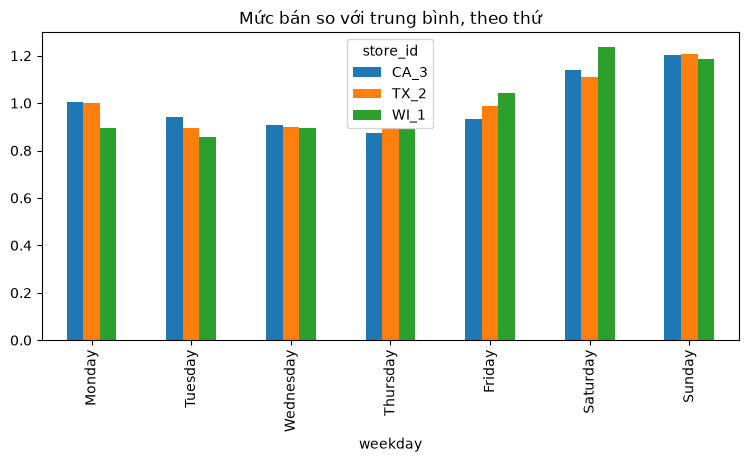

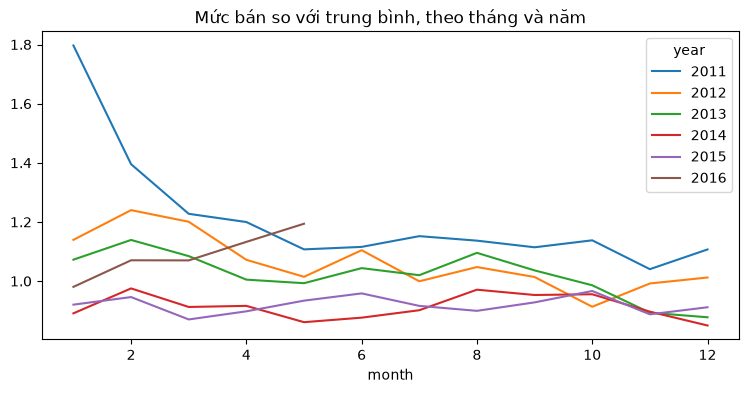

In [7]:
print(live["weekday"].unique())
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
wk = live.pivot_table(index="weekday", columns="store_id", values="rel", aggfunc="mean").reindex(order)
print(wk.round(2))
wk.plot(kind="bar", figsize=(9, 4), title="Mức bán so với trung bình, theo thứ"); plt.show()

mo = live.pivot_table(index="month", columns="year", values="rel", aggfunc="mean")
mo.plot(figsize=(9, 4), title="Mức bán so với trung bình, theo tháng và năm"); plt.show()

In [7]:
full = live[live["year"].between(2012, 2015)].copy()
full["yr_mean"] = full.groupby(["id", "year"])["sales"].transform("mean")
full = full[full["yr_mean"] > 0]
full["rel_year"] = full["sales"] / full["yr_mean"]

print(full.pivot_table(index="month", columns="year", values="rel_year", aggfunc="mean").round(2))
print(full.groupby("month")["rel_year"].mean().round(3))

year   2012  2013  2014  2015
month                        
1      1.15  1.12  1.09  1.07
2      1.18  1.12  1.10  1.10
3      1.16  1.05  0.98  0.96
4      1.00  0.92  0.98  0.96
5      1.00  0.95  0.92  0.99
6      1.04  1.01  0.94  1.02
7      0.87  0.99  0.95  0.98
8      0.94  1.06  1.04  0.93
9      0.90  1.03  1.04  0.95
10     0.86  0.96  1.03  1.04
11     1.00  0.91  1.00  0.97
12     1.00  0.90  0.94  1.01
month
1     1.103
2     1.120
3     1.027
4     0.965
5     0.963
6     1.000
7     0.954
8     0.996
9     0.986
10    0.979
11    0.969
12    0.961
Name: rel_year, dtype: float64


In [9]:
live["has_event"] = live["event_name_1"].notna() | live["event_name_2"].notna()
print(live.groupby("has_event")["rel"].mean().round(3))
print(live.groupby("snap")["rel"].mean().round(3))
print(live.groupby(["store_id", "snap"])["rel"].mean().unstack().round(3))

print(live.groupby("event_type_1")["rel"].agg(["mean", "count"]).round(3))
ev = live.groupby("event_name_1")["rel"].agg(["mean", "count"]).sort_values("mean")
print(ev.head(5).round(3)); print(ev.tail(5).round(3))

has_event
False    1.003
True     0.965
Name: rel, dtype: float64
snap
0    0.958
1    1.086
Name: rel, dtype: float64
snap          0      1
store_id              
CA_3      0.958  1.085
TX_2      0.944  1.114
WI_1      0.973  1.056
               mean  count
event_type_1              
Cultural      1.041   9468
National      0.823  13285
Religious     1.012  13852
Sporting      1.094   3994
                  mean  count
event_name_1                 
Christmas        0.000   1336
Thanksgiving     0.443   1334
NewYear          0.740   1340
IndependenceDay  0.868   1264
Halloween        0.881   1326
                 mean  count
event_name_1                
Easter          1.097   1378
ValentinesDay   1.137   1492
LaborDay        1.214   1288
SuperBowl       1.285   1482
OrthodoxEaster  1.320   1243


In [10]:
print(live.nlargest(5, "sales")[["id", "date", "sales", "sell_price", "event_name_1"]])
print(live["sales"].quantile([0.9, 0.99, 0.999]))

xmas = live[live["event_name_1"] == "Christmas"]
print(xmas.groupby("year")["sales"].agg(["sum", "count"]))

                                 id       date  sales  sell_price event_name_1
361985  FOODS_3_090_CA_3_evaluation 2013-09-14    763        1.00          NaN
361963  FOODS_3_090_CA_3_evaluation 2013-08-23    709        1.00          NaN
361984  FOODS_3_090_CA_3_evaluation 2013-09-13    709        1.00          NaN
361362  FOODS_3_090_CA_3_evaluation 2011-12-31    693        1.28          NaN
361354  FOODS_3_090_CA_3_evaluation 2011-12-23    633        1.28          NaN
0.900      6.000
0.990     31.000
0.999    186.283
Name: sales, dtype: float64
      sum  count
year            
2011    1    176
2012    0    269
2013    0    297
2014    0    297
2015    0    297


       n_prices     pmin     pmax     pmed  max_over_min
count   297.000  297.000  297.000  297.000       297.000
mean      3.909    2.901    3.653    3.431         1.411
std       2.521    1.816    2.297    2.106         1.482
min       1.000    0.150    0.250    0.200         1.000
25%       2.000    1.500    1.980    1.980         1.075
50%       4.000    2.470    2.970    2.780         1.175
75%       5.000    3.980    4.980    4.740         1.333
max      14.000    9.270   13.980   11.970        24.182
tỉ lệ chuỗi giá không bao giờ đổi: 0.152
số lần đổi giá mỗi chuỗi:
count    297.00
mean       4.58
std        4.35
min        0.00
25%        1.00
50%        4.00
75%        7.00
max       25.00
dtype: float64
độ lớn mỗi lần đổi (giá trị tuyệt đối, %):
count    1361.00
mean       18.73
std        57.03
min         0.14
25%         4.37
50%        10.16
75%        18.67
max      1709.09
Name: price_pct, dtype: float64


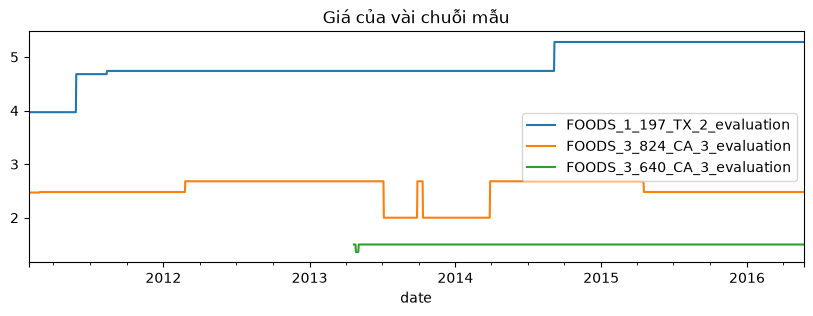

               mean   count
price_bin                  
(0.0, 0.8]    0.974    6503
(0.8, 0.95]   1.092   47006
(0.95, 1.05]  1.008  383088
(1.05, 1.2]   0.903   60287
(1.2, 10.0]   0.511    2834


In [11]:
# giá của từng chuỗi: có bao nhiêu mức giá khác nhau, chênh lệch bao nhiêu
sp = live.groupby("id")["sell_price"].agg(n_prices="nunique", pmin="min", pmax="max", pmed="median")
sp["max_over_min"] = sp["pmax"] / sp["pmin"]
print(sp.describe().round(3))
print("tỉ lệ chuỗi giá không bao giờ đổi:", round((sp["n_prices"] == 1).mean(), 3))

# số lần đổi giá và độ lớn mỗi lần đổi (live đã sắp theo id, date từ Cell 2)
prev = live.groupby("id")["sell_price"].shift()
live["price_pct"] = live["sell_price"] / prev - 1          # NaN ở ngày đầu của mỗi chuỗi
chg = live[live["price_pct"].fillna(0) != 0]
print("số lần đổi giá mỗi chuỗi:")
print(chg.groupby("id").size().reindex(sp.index, fill_value=0).describe().round(2))
print("độ lớn mỗi lần đổi (giá trị tuyệt đối, %):")
print((chg["price_pct"].abs() * 100).describe().round(2))

# vẽ giá của 3 chuỗi có đổi giá
cands = pd.Series(sp.index[sp["n_prices"] > 1])
for i in cands.sample(min(3, len(cands)), random_state=1):
    live.loc[live["id"] == i].set_index("date")["sell_price"].plot(label=i, figsize=(10, 3))
plt.legend(); plt.title("Giá của vài chuỗi mẫu"); plt.show()

# doanh số khi giá cao hay thấp hơn giá thông thường của chính chuỗi đó
live["price_rel"] = live["sell_price"] / live.groupby("id")["sell_price"].transform("median")
live["price_bin"] = pd.cut(live["price_rel"], [0, 0.8, 0.95, 1.05, 1.2, 10])
print(live.groupby("price_bin", observed=True)["rel"].agg(["mean", "count"]).round(3))

In [12]:
long.to_parquet(PROC / "subset_long.parquet", index=False)

count    1941.0
mean      130.8
std       107.9
min         0.0
25%        53.0
50%       125.0
75%       188.0
max       763.0
Name: sales, dtype: float64
số chuỗi trung bình > 50/ngày: 1


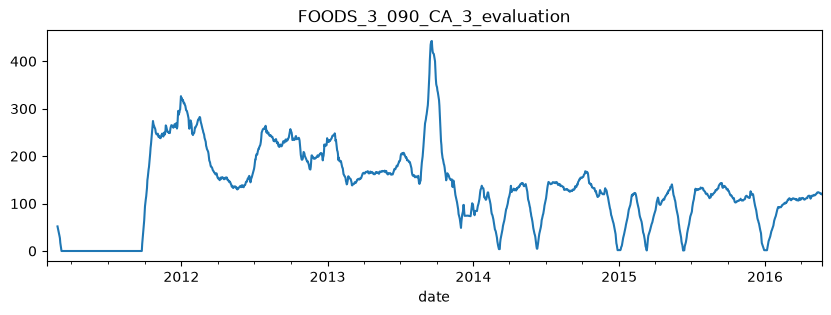

id
FOODS_2_281_TX_2_evaluation    24.18
FOODS_1_114_CA_3_evaluation    10.11
FOODS_3_352_CA_3_evaluation     4.38
Name: max_over_min, dtype: float64
             date  sell_price  price_pct
272041 2011-11-26        6.98   0.167224
272860 2014-02-22        5.97  -0.144699
272867 2014-03-01        0.33  -0.944724
272874 2014-03-08        5.97  17.090909
272993 2014-07-05        7.98   0.336683
273266 2015-04-04        6.86  -0.140351
273413 2015-08-29        6.46  -0.058309
273441 2015-09-26        7.98   0.235294
                             pmin  pmax
id                                     
FOODS_3_547_WI_1_evaluation  0.15  0.25
FOODS_2_281_TX_2_evaluation  0.33  7.98
FOODS_1_114_CA_3_evaluation  0.35  3.54
year
2011    0.967
2012    0.997
2013    0.995
2014    1.001
2015    1.015
2016    1.017
Name: price_rel, dtype: float64
price_bin  (0.0, 0.8]  (0.8, 0.95]  (0.95, 1.05]  (1.05, 1.2]  (1.2, 10.0]
year                                                                      
2011       

In [13]:
# (a) chuỗi bán rất chạy
big = "FOODS_3_090_CA_3_evaluation"
s = live[live["id"] == big]
print(s["sales"].describe().round(1))
print("số chuỗi trung bình > 50/ngày:", (live.groupby("id")["sales"].mean() > 50).sum())
s.set_index("date")["sales"].rolling(28).mean().plot(figsize=(10, 3), title=big)
plt.show()

# (b) chuỗi có giá nhảy bất thường, và chuỗi giá thấp nhất
top = sp["max_over_min"].nlargest(3)
print(top.round(2))
w = live[live["id"] == top.index[0]][["date", "sell_price", "price_pct"]]
print(w[w["price_pct"].fillna(0) != 0])
print(sp.nsmallest(3, "pmin")[["pmin", "pmax"]])

# (c) giá có xu hướng theo năm không, và tác động của giá khi đã cố định năm
print(live.groupby("year")["price_rel"].mean().round(3))
print(live.groupby(["year", "price_bin"], observed=True)["rel"].mean().unstack().round(2))